<a href="https://colab.research.google.com/github/shefiramarizcha62-sudo/flyrank-ml-portfolio/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shefiramarizcha62-sudo/flyrank-ml-portfolio/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## Content Opportunity Scoring for Search Performance

### Abstract

This study investigates how observable search and content performance signals can be used to prioritize client-content pairs for human review. A Random Forest classifier was developed using six features derived from March 2026 search and engagement data, with an April 2026 proxy outcome defined by impression and click-through rate thresholds. The model was evaluated using a client-grouped train-test split and compared with a rule-based baseline on the same test set. The Random Forest achieved a ROC-AUC of 0.921432 and an Average Precision of 0.680600, outperforming the baseline scores of 0.738707 and 0.318966, respectively. These findings support the use of model-based scoring as a decision-support approach for prioritizing content and SEO reviews, rather than as evidence of causal improvements in Google Search performance.

### Introduction

Search performance data provides useful signals for understanding how content performs in organic search. Metrics such as impressions, clicks, click-through rate (CTR), and average search position can help identify differences in content visibility and user engagement.

However, when managing a large number of client-content pairs, identifying which candidates should receive attention first can be challenging. Some pairs may receive substantial search impressions but generate relatively few clicks, indicating a potential opportunity to review their search presentation and content alignment. Reviewing all pairs manually may also require considerable time and effort.

To address this challenge, this study develops a machine learning-based content opportunity scoring approach using historical search and content performance signals. The approach combines a rule-based baseline and a Random Forest classifier to identify and rank client-content pairs associated with a predefined future low-CTR condition.

The resulting ranked queue is intended to help content and SEO reviewers prioritize candidates for further investigation. Each candidate is accompanied by a model score, a reason code, and a recommended action to support human review. The approach does not automatically modify content or guarantee improvements in search performance.

## 1. Question

### Research Question

Can March search and content performance signals be used to identify and prioritize client-content pairs with future search opportunity, particularly those receiving sufficient impressions but experiencing low click-through rates?

### Problem Statement

Content teams may manage a large number of pages, making it difficult to identify which pages deserve attention first. Pages with substantial search visibility but relatively low click-through rates may represent opportunities for further content or metadata review.

This project develops a machine learning-based scoring approach to prioritize client-content pairs using historical search and content performance signals. The model uses March 2026 observations to identify pairs associated with a predefined low-CTR opportunity condition in April 2026.

### Decision Supported

The system supports content and SEO reviewers in prioritizing which client-content pairs should be examined first. Each candidate receives a model score, a reason code, and a recommended review action.

The output is intended as a human-in-the-loop decision-support tool. It does not automatically modify content or establish that refreshing a page will improve its search performance.

### Scope

- **Selected lane:** Refresh / Content Opportunity Scoring.
- **Unit of analysis:** Client-content pair.
- **Observation window:** March 2026.
- **Outcome window:** April 2026.
- **Primary output:** Ranked content opportunity queue with interpretable reason codes and recommended actions.

In [ ]:
# ==========================================
# 1. CAPSTONE PROJECT DEFINITION
# ==========================================

PROJECT_TITLE = "Content Opportunity Scoring for Search Performance"

SELECTED_LANE = "Refresh / Content Opportunity Scoring"

RESEARCH_QUESTION = (
    "Can March search and content performance signals "
    "identify client-content pairs associated with "
    "future low-CTR opportunities?"
)

UNIT_OF_ANALYSIS = "client-content pair"

OBSERVATION_WINDOW = "2026-03-01 to 2026-03-31"
OUTCOME_WINDOW = "2026-04-01 to 2026-04-30"

DECISION_SUPPORTED = (
    "Prioritize client-content pairs for human content "
    "and SEO review."
)

OUTPUTS = [
    "model_score",
    "rank",
    "reason_code",
    "recommended_action"
]

# Basic consistency checks
assert SELECTED_LANE == "Refresh / Content Opportunity Scoring"
assert UNIT_OF_ANALYSIS == "client-content pair"
assert len(OUTPUTS) == 4

print("Capstone project definition")
print("=" * 45)
print("Title:", PROJECT_TITLE)
print("Lane:", SELECTED_LANE)
print("Unit of analysis:", UNIT_OF_ANALYSIS)
print("Observation window:", OBSERVATION_WINDOW)
print("Outcome window:", OUTCOME_WINDOW)
print("Decision:", DECISION_SUPPORTED)
print("Outputs:", OUTPUTS)
print("\nSection 1 validation: PASS")

Capstone project definition
Title: Content Opportunity Scoring for Search Performance
Lane: Refresh / Content Opportunity Scoring
Unit of analysis: client-content pair
Observation window: 2026-03-01 to 2026-03-31
Outcome window: 2026-04-01 to 2026-04-30
Decision: Prioritize client-content pairs for human content and SEO review.
Outputs: ['model_score', 'rank', 'reason_code', 'recommended_action']

Section 1 validation: PASS


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*


### 2.1 Data Source

This study uses the FlyRank internship warehouse dataset, accessed through the Hugging Face dataset repository `FlyRank/internship-warehouse`.

The source table is `fact_content_daily_performance`, which contains daily search and content performance observations.

The analysis uses two monthly data windows:

- **Observation window:** March 1–31, 2026.
- **Outcome window:** April 1–30, 2026.

March data provides historical features, while April data is used to construct the future opportunity label.

### 2.2 Data Granularity and Aggregation

The raw dataset is organized at the daily client-content observation level. For modeling, daily records are aggregated into client-content pairs using `client_hash_id` and `content_hash_id`.

The aggregation process summarizes search and content performance metrics across the observation window.

The resulting modeling unit is one client-content pair, rather than an individual daily observation.

### 2.3 Dataset Scope

The March 2026 dataset contains 9,841,378 raw observations and 331,437 aggregated client-content pairs.

The April 2026 dataset contains 10,424,730 raw observations.

After joining the March features and April outcomes using the client-content identifiers, the modeling dataset contains 331,436 pairs.

### 2.4 Feature Selection

The model uses six March performance features:

1. `gsc_impressions`
2. `gsc_clicks`
3. `march_ctr`
4. `gsc_avg_position`
5. `ga4_pageviews`
6. `ga4_engaged_sessions`

These features represent search visibility, click performance, search position, and website engagement.

### 2.5 Target Definition

The target variable is `future_opportunity`, constructed from April performance.

A client-content pair is assigned a positive label when April impressions exceed 100 and April CTR is below 0.001. Otherwise, it receives a negative label.

The target is a predefined operational proxy for a future low-CTR opportunity. It is not a verified label of actual content refresh necessity or successful content improvement.

### 2.6 Excluded Variables

April performance variables are excluded from model features because they are used to construct the target.

Identifiers such as `client_hash_id` and `content_hash_id` are used for aggregation, joining, and grouped validation, but are not model features.

Target variables, baseline scores, reason codes, and recommended actions are also excluded from the feature set to prevent target leakage.

### 2.7 Data Limitations

The source data contains substantial missingness in Google Search Console metrics. In the March data, 3,611,061 observations have available GSC data, while 6,230,317 observations are unavailable or missing.

Consequently, missing values must be handled carefully during preprocessing, and the resulting model should be interpreted in the context of data coverage limitations.

In [ ]:
# ==========================================
# 2. DATA SOURCE AND CONFIGURATION
# ==========================================

DATASET_ID = "FlyRank/internship-warehouse"
SOURCE_TABLE = "fact_content_daily_performance"

MARCH_PATH = (
    "hf://datasets/FlyRank/internship-warehouse/"
    "fact_content_daily_performance/"
    "month=2026-03/data_0.parquet"
)

APRIL_PATH = (
    "hf://datasets/FlyRank/internship-warehouse/"
    "fact_content_daily_performance/"
    "month=2026-04/data_0.parquet"
)

JOIN_KEYS = [
    "client_hash_id",
    "content_hash_id"
]

FEATURE_COLUMNS = [
    "gsc_impressions",
    "gsc_clicks",
    "march_ctr",
    "gsc_avg_position",
    "ga4_pageviews",
    "ga4_engaged_sessions"
]

IDENTIFIER_COLUMNS = [
    "client_hash_id",
    "content_hash_id"
]

TARGET_COLUMN = "future_opportunity"

MARCH_RAW_ROWS = 9_841_378
MARCH_AGGREGATED_PAIRS = 331_437
APRIL_RAW_ROWS = 10_424_730
MODELING_ROWS = 331_436

print("DATA CONFIGURATION")
print("=" * 45)
print("Dataset:", DATASET_ID)
print("Source table:", SOURCE_TABLE)
print("Join keys:", JOIN_KEYS)
print("Feature columns:", FEATURE_COLUMNS)
print("Target:", TARGET_COLUMN)

print("\nHISTORICAL DATA SUMMARY")
print("=" * 45)
print("March raw rows:", f"{MARCH_RAW_ROWS:,}")
print("March aggregated pairs:", f"{MARCH_AGGREGATED_PAIRS:,}")
print("April raw rows:", f"{APRIL_RAW_ROWS:,}")
print("Final modeling rows:", f"{MODELING_ROWS:,}")

assert len(FEATURE_COLUMNS) == 6
assert len(JOIN_KEYS) == 2
assert TARGET_COLUMN not in FEATURE_COLUMNS

print("\nSection 2 configuration: PASS")

DATA CONFIGURATION
Dataset: FlyRank/internship-warehouse
Source table: fact_content_daily_performance
Join keys: ['client_hash_id', 'content_hash_id']
Feature columns: ['gsc_impressions', 'gsc_clicks', 'march_ctr', 'gsc_avg_position', 'ga4_pageviews', 'ga4_engaged_sessions']
Target: future_opportunity

HISTORICAL DATA SUMMARY
March raw rows: 9,841,378
March aggregated pairs: 331,437
April raw rows: 10,424,730
Final modeling rows: 331,436

Section 2 configuration: PASS


In [ ]:
# ==========================================
# FEATURE AND TARGET SPECIFICATION
# ==========================================

TARGET_RULE = {
    "positive_condition": [
        "april_impressions > 100",
        "april_ctr < 0.001"
    ],
    "positive_label": 1,
    "negative_label": 0
}

EXCLUDED_FROM_FEATURES = [
    "client_hash_id",
    "content_hash_id",
    "april_impressions",
    "april_clicks",
    "april_ctr",
    "future_opportunity",
    "baseline_score",
    "reason_code",
    "recommended_action"
]

print("FEATURES")
for feature in FEATURE_COLUMNS:
    print("-", feature)

print("\nTARGET RULE")
print(TARGET_RULE)

print("\nEXCLUDED VARIABLES")
for column in EXCLUDED_FROM_FEATURES:
    print("-", column)

assert "april_ctr" not in FEATURE_COLUMNS
assert "april_impressions" not in FEATURE_COLUMNS
assert TARGET_COLUMN not in FEATURE_COLUMNS

print("\nFeature-target specification: PASS")

FEATURES
- gsc_impressions
- gsc_clicks
- march_ctr
- gsc_avg_position
- ga4_pageviews
- ga4_engaged_sessions

TARGET RULE
{'positive_condition': ['april_impressions > 100', 'april_ctr < 0.001'], 'positive_label': 1, 'negative_label': 0}

EXCLUDED VARIABLES
- client_hash_id
- content_hash_id
- april_impressions
- april_clicks
- april_ctr
- future_opportunity
- baseline_score
- reason_code
- recommended_action

Feature-target specification: PASS


### 2.8 Data Aggregation and Join

Daily observations from March 2026 are aggregated by `client_hash_id` and `content_hash_id`.

The aggregation summarizes the following metrics:

- `gsc_impressions`: sum of daily impressions.
- `gsc_clicks`: sum of daily clicks.
- `gsc_avg_position`: mean of daily average positions.
- `ga4_pageviews`: sum of daily pageviews.
- `ga4_engaged_sessions`: sum of daily engaged sessions.

March CTR is calculated as total clicks divided by total impressions. When total impressions are zero, CTR is set to zero.

April observations are aggregated using the same client-content keys. April CTR is calculated from aggregated clicks and impressions and is used only to construct the future opportunity target.

The March and April aggregates are joined using an inner join on `client_hash_id` and `content_hash_id`. Consequently, only pairs present in both monthly datasets are retained for modeling.

The final joined dataset contains 331,436 client-content pairs.

In [ ]:
# ==========================================
# DATA AGGREGATION SPECIFICATION
# ==========================================

MARCH_AGGREGATION = {
    "gsc_impressions": "sum",
    "gsc_clicks": "sum",
    "gsc_avg_position": "mean",
    "ga4_pageviews": "sum",
    "ga4_engaged_sessions": "sum"
}

APRIL_AGGREGATION = {
    "april_impressions": "sum",
    "april_clicks": "sum"
}

AGGREGATION_KEYS = [
    "client_hash_id",
    "content_hash_id"
]

JOIN_TYPE = "inner"

print("AGGREGATION KEYS:", AGGREGATION_KEYS)

print("\nMARCH AGGREGATION")
for column, method in MARCH_AGGREGATION.items():
    print(f"{column}: {method}")

print("\nAPRIL AGGREGATION")
for column, method in APRIL_AGGREGATION.items():
    print(f"{column}: {method}")

print("\nJOIN TYPE:", JOIN_TYPE)

assert set(AGGREGATION_KEYS) == set(JOIN_KEYS)
assert JOIN_TYPE == "inner"

print("\nAggregation specification: PASS")

AGGREGATION KEYS: ['client_hash_id', 'content_hash_id']

MARCH AGGREGATION
gsc_impressions: sum
gsc_clicks: sum
gsc_avg_position: mean
ga4_pageviews: sum
ga4_engaged_sessions: sum

APRIL AGGREGATION
april_impressions: sum
april_clicks: sum

JOIN TYPE: inner

Aggregation specification: PASS


In [ ]:
# ==========================================
# FUTURE OPPORTUNITY TARGET
# ==========================================

APRIL_IMPRESSIONS_THRESHOLD = 100
APRIL_CTR_THRESHOLD = 0.001

def create_future_opportunity(df):
    """
    Create a binary future opportunity proxy label.

    Positive (1):
        April impressions > 100
        AND April CTR < 0.001

    Negative (0):
        All other conditions.
    """
    return (
        (df["april_impressions"] > APRIL_IMPRESSIONS_THRESHOLD)
        & (df["april_ctr"] < APRIL_CTR_THRESHOLD)
    ).astype(int)


print("TARGET DEFINITION")
print("=" * 40)
print("Positive condition:")
print(f"- April impressions > {APRIL_IMPRESSIONS_THRESHOLD}")
print(f"- April CTR < {APRIL_CTR_THRESHOLD}")

print("\nNegative condition:")
print("- All other conditions")

print("\nTarget specification: PASS")

TARGET DEFINITION
Positive condition:
- April impressions > 100
- April CTR < 0.001

Negative condition:
- All other conditions

Target specification: PASS


### 2.9 Data Quality and Target Distribution

The modeling dataset is evaluated in terms of record counts, missing values, and target distribution.

The expected modeling dataset contains 331,436 client-content pairs after joining March features with April outcomes.

The binary target is expected to be imbalanced, with approximately 84.48% negative observations and 15.52% positive observations.

Missing values are handled during model preprocessing. Imputation parameters must be learned from training data only to avoid information leakage into the test set.

The data quality assessment is used to verify dataset consistency before model training and evaluation.

In [ ]:
# ==========================================
# EXPECTED TARGET DISTRIBUTION FROM W5
# ==========================================

EXPECTED_TARGET_COUNTS = {
    0: 280_002,
    1: 51_434
}

EXPECTED_TOTAL = sum(EXPECTED_TARGET_COUNTS.values())

print("REFERENCE TARGET DISTRIBUTION — W5")
print("=" * 45)

for label, count in EXPECTED_TARGET_COUNTS.items():
    percentage = count / EXPECTED_TOTAL * 100
    label_name = "Negative" if label == 0 else "Positive"

    print(
        f"{label_name} ({label}): "
        f"{count:,} ({percentage:.2f}%)"
    )

print("-" * 45)
print("Total:", f"{EXPECTED_TOTAL:,}")

assert EXPECTED_TOTAL == MODELING_ROWS

print("\nReference distribution check: PASS")

REFERENCE TARGET DISTRIBUTION — W5
Negative (0): 280,002 (84.48%)
Positive (1): 51,434 (15.52%)
---------------------------------------------
Total: 331,436

Reference distribution check: PASS


In [ ]:
# ==========================================
# DATA QUALITY VALIDATION FUNCTION
# ==========================================

def validate_modeling_data(df):
    required_columns = (
        JOIN_KEYS
        + FEATURE_COLUMNS
        + ["april_impressions", "april_ctr", TARGET_COLUMN]
    )

    missing_columns = [
        column for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    print("DATA QUALITY REPORT")
    print("=" * 45)

    print("Rows:", f"{len(df):,}")

    print(
        "Unique client-content pairs:",
        f"{df[JOIN_KEYS].drop_duplicates().shape[0]:,}"
    )

    print("\nMissing values:")
    print(df[FEATURE_COLUMNS].isna().sum())

    print("\nTarget distribution:")
    print(df[TARGET_COLUMN].value_counts(dropna=False))

    print("\nTarget percentage:")
    print(
        df[TARGET_COLUMN]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )

    assert not df[TARGET_COLUMN].isna().any()
    assert set(df[TARGET_COLUMN].unique()).issubset({0, 1})

    print("\nData quality validation: PASS")

In [ ]:
# ==========================================
# CONNECT TO FLYRANK WAREHOUSE
# ==========================================

from google.colab import userdata
import duckdb
import pandas as pd
import numpy as np

HF_TOKEN = userdata.get("FlyRank-ML")

if not HF_TOKEN:
    raise ValueError(
        "FlyRank-ML token not found in Colab Secrets."
    )

con = duckdb.connect()

con.execute(f"""
    CREATE SECRET hf_secret (
        TYPE HUGGINGFACE,
        TOKEN '{HF_TOKEN}'
    );
""")

print("Hugging Face token loaded:", HF_TOKEN is not None)
print("DuckDB connected:", con is not None)
print("Warehouse authentication: PASS")

Hugging Face token loaded: True
DuckDB connected: True
Warehouse authentication: PASS


In [ ]:
# ==========================================
# LOAD AND AGGREGATE MARCH FEATURES
# ==========================================

feature_frame = con.execute("""
    SELECT
        client_hash_id,
        content_hash_id,
        report_date,
        gsc_impressions,
        gsc_clicks,
        gsc_avg_position,
        ga4_pageviews,
        ga4_engaged_sessions
    FROM read_parquet(
        'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-03/data_0.parquet'
    )
    WHERE month = '2026-03'
""").df()

print("March feature rows:", f"{len(feature_frame):,}")
print(
    "March date range:",
    feature_frame["report_date"].min(),
    "to",
    feature_frame["report_date"].max()
)

march_features = (
    feature_frame
    .groupby(
        JOIN_KEYS,
        as_index=False
    )
    .agg(
        gsc_impressions=("gsc_impressions", "sum"),
        gsc_clicks=("gsc_clicks", "sum"),
        gsc_avg_position=("gsc_avg_position", "mean"),
        ga4_pageviews=("ga4_pageviews", "sum"),
        ga4_engaged_sessions=("ga4_engaged_sessions", "sum")
    )
)

march_features["march_ctr"] = (
    march_features["gsc_clicks"]
    / march_features["gsc_impressions"].replace(0, np.nan)
).fillna(0)

print("\nMarch aggregated pairs:", f"{len(march_features):,}")
print("\nMarch feature preview:")
display(march_features.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

March feature rows: 9,841,378
March date range: 2026-03-01 00:00:00 to 2026-03-31 00:00:00

March aggregated pairs: 331,437

March feature preview:


,client_hash_id,content_hash_id,gsc_impressions,gsc_clicks,gsc_avg_position,ga4_pageviews,ga4_engaged_sessions,march_ctr
0,client_0797ff3a1fc9a6a5,content_004e9c4c32e88631,0,0,NaN,0,0,0.0
1,client_0797ff3a1fc9a6a5,content_0236ef736698e17c,0,0,NaN,0,0,0.0
2,client_0797ff3a1fc9a6a5,content_025f6cfd3c298870,0,0,NaN,0,0,0.0
3,client_0797ff3a1fc9a6a5,content_0263d5f9b7a2ecd4,1,0,9.0,0,0,0.0
4,client_0797ff3a1fc9a6a5,content_02752c6c1c60161f,0,0,NaN,0,0,0.0


In [ ]:
# ==========================================
# LOAD AND AGGREGATE APRIL OUTCOMES
# ==========================================

april_outcome = con.execute("""
    SELECT
        client_hash_id,
        content_hash_id,
        report_date,
        gsc_impressions,
        gsc_clicks
    FROM read_parquet(
        'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-04/data_0.parquet'
    )
    WHERE month = '2026-04'
""").df()

print("April outcome rows:", f"{len(april_outcome):,}")
print(
    "April date range:",
    april_outcome["report_date"].min(),
    "to",
    april_outcome["report_date"].max()
)

april_outcome = (
    april_outcome
    .groupby(
        JOIN_KEYS,
        as_index=False
    )
    .agg(
        april_impressions=("gsc_impressions", "sum"),
        april_clicks=("gsc_clicks", "sum")
    )
)

april_outcome["april_ctr"] = (
    april_outcome["april_clicks"]
    / april_outcome["april_impressions"].replace(0, np.nan)
).fillna(0)

print("\nApril aggregated pairs:", f"{len(april_outcome):,}")
display(april_outcome.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

April outcome rows: 10,424,730
April date range: 2026-04-01 00:00:00 to 2026-04-30 00:00:00

April aggregated pairs: 362,172


,client_hash_id,content_hash_id,april_impressions,april_clicks,april_ctr
0,client_06d356715a8ff3b6,content_0059a4d4195810c9,873,2,0.002291
1,client_06d356715a8ff3b6,content_005b6b7f7b8dda7f,634,1,0.001577
2,client_06d356715a8ff3b6,content_0153b7dedc3fc40d,640,2,0.003125
3,client_06d356715a8ff3b6,content_0241f6a890063db0,85,1,0.011765
4,client_06d356715a8ff3b6,content_045f673b3d3c18a4,153,2,0.013072


In [ ]:
# ==========================================
# JOIN MARCH FEATURES AND APRIL OUTCOMES
# ==========================================

model_df = march_features.merge(
    april_outcome,
    on=JOIN_KEYS,
    how="inner"
)

print("Modeling rows:", f"{len(model_df):,}")

print(
    "Unique client-content pairs:",
    f"{model_df[JOIN_KEYS].drop_duplicates().shape[0]:,}"
)

# Create future opportunity proxy label
model_df[TARGET_COLUMN] = create_future_opportunity(model_df)

print("\nTarget distribution:")
print(model_df[TARGET_COLUMN].value_counts().sort_index())

print("\nTarget percentage:")
print(
    model_df[TARGET_COLUMN]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(
    model_df[
        FEATURE_COLUMNS
        + ["april_impressions", "april_ctr", TARGET_COLUMN]
    ].head()
)

Modeling rows: 331,436
Unique client-content pairs: 331,436

Target distribution:
future_opportunity
0    280002
1     51434
Name: count, dtype: int64

Target percentage:
future_opportunity
0    84.48
1    15.52
Name: proportion, dtype: float64


,gsc_impressions,gsc_clicks,march_ctr,gsc_avg_position,ga4_pageviews,ga4_engaged_sessions,april_impressions,april_ctr,future_opportunity
0,0,0,0.0,NaN,0,0,0,0.0,0
1,0,0,0.0,NaN,0,0,0,0.0,0
2,0,0,0.0,NaN,0,0,0,0.0,0
3,1,0,0.0,9.0,0,0,15,0.0,0
4,0,0,0.0,NaN,0,0,0,0.0,0


In [ ]:
validate_modeling_data(model_df)

DATA QUALITY REPORT
Rows: 331,436
Unique client-content pairs: 331,436

Missing values:
gsc_impressions              0
gsc_clicks                   0
march_ctr                    0
gsc_avg_position        154699
ga4_pageviews                0
ga4_engaged_sessions         0
dtype: int64

Target distribution:
future_opportunity
0    280002
1     51434
Name: count, dtype: int64

Target percentage:
future_opportunity
0    84.48
1    15.52
Name: proportion, dtype: float64

Data quality validation: PASS


### 2.10 Data Quality Assessment Results

The rebuilt modeling dataset contains 331,436 unique client-content pairs after the inner join of March features and April outcomes.

The target distribution consists of 280,002 negative observations (84.48%) and 51,434 positive observations (15.52%), confirming the class imbalance observed in the previous modeling experiments.

Among the six selected features, `gsc_avg_position` contains 154,699 missing values, representing approximately 46.68% of the modeling dataset. The remaining five features contain no missing values.

The missing position values are retained rather than removing affected observations. They are handled through median imputation during model preprocessing.

The dataset reconstruction reproduces the row counts and target distribution from the previous modeling workflow. These checks support consistency between the original experiments and the capstone implementation.

In [ ]:
# ==========================================
# FINAL SECTION 2 VALIDATION
# ==========================================

assert len(model_df) == 331_436

assert (
    model_df[JOIN_KEYS]
    .drop_duplicates()
    .shape[0] == len(model_df)
)

assert model_df[TARGET_COLUMN].value_counts().to_dict() == {
    0: 280_002,
    1: 51_434
}

assert model_df["gsc_avg_position"].isna().sum() == 154_699

assert model_df[FEATURE_COLUMNS].isna().sum().to_dict() == {
    "gsc_impressions": 0,
    "gsc_clicks": 0,
    "march_ctr": 0,
    "gsc_avg_position": 154_699,
    "ga4_pageviews": 0,
    "ga4_engaged_sessions": 0
}

print("FINAL DATA VALIDATION")
print("=" * 45)
print("Modeling rows: PASS")
print("Unique client-content pairs: PASS")
print("Target distribution: PASS")
print("Missing-value verification: PASS")
print("\nSection 2: COMPLETE")

FINAL DATA VALIDATION
Modeling rows: PASS
Unique client-content pairs: PASS
Target distribution: PASS
Missing-value verification: PASS

Section 2: COMPLETE


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

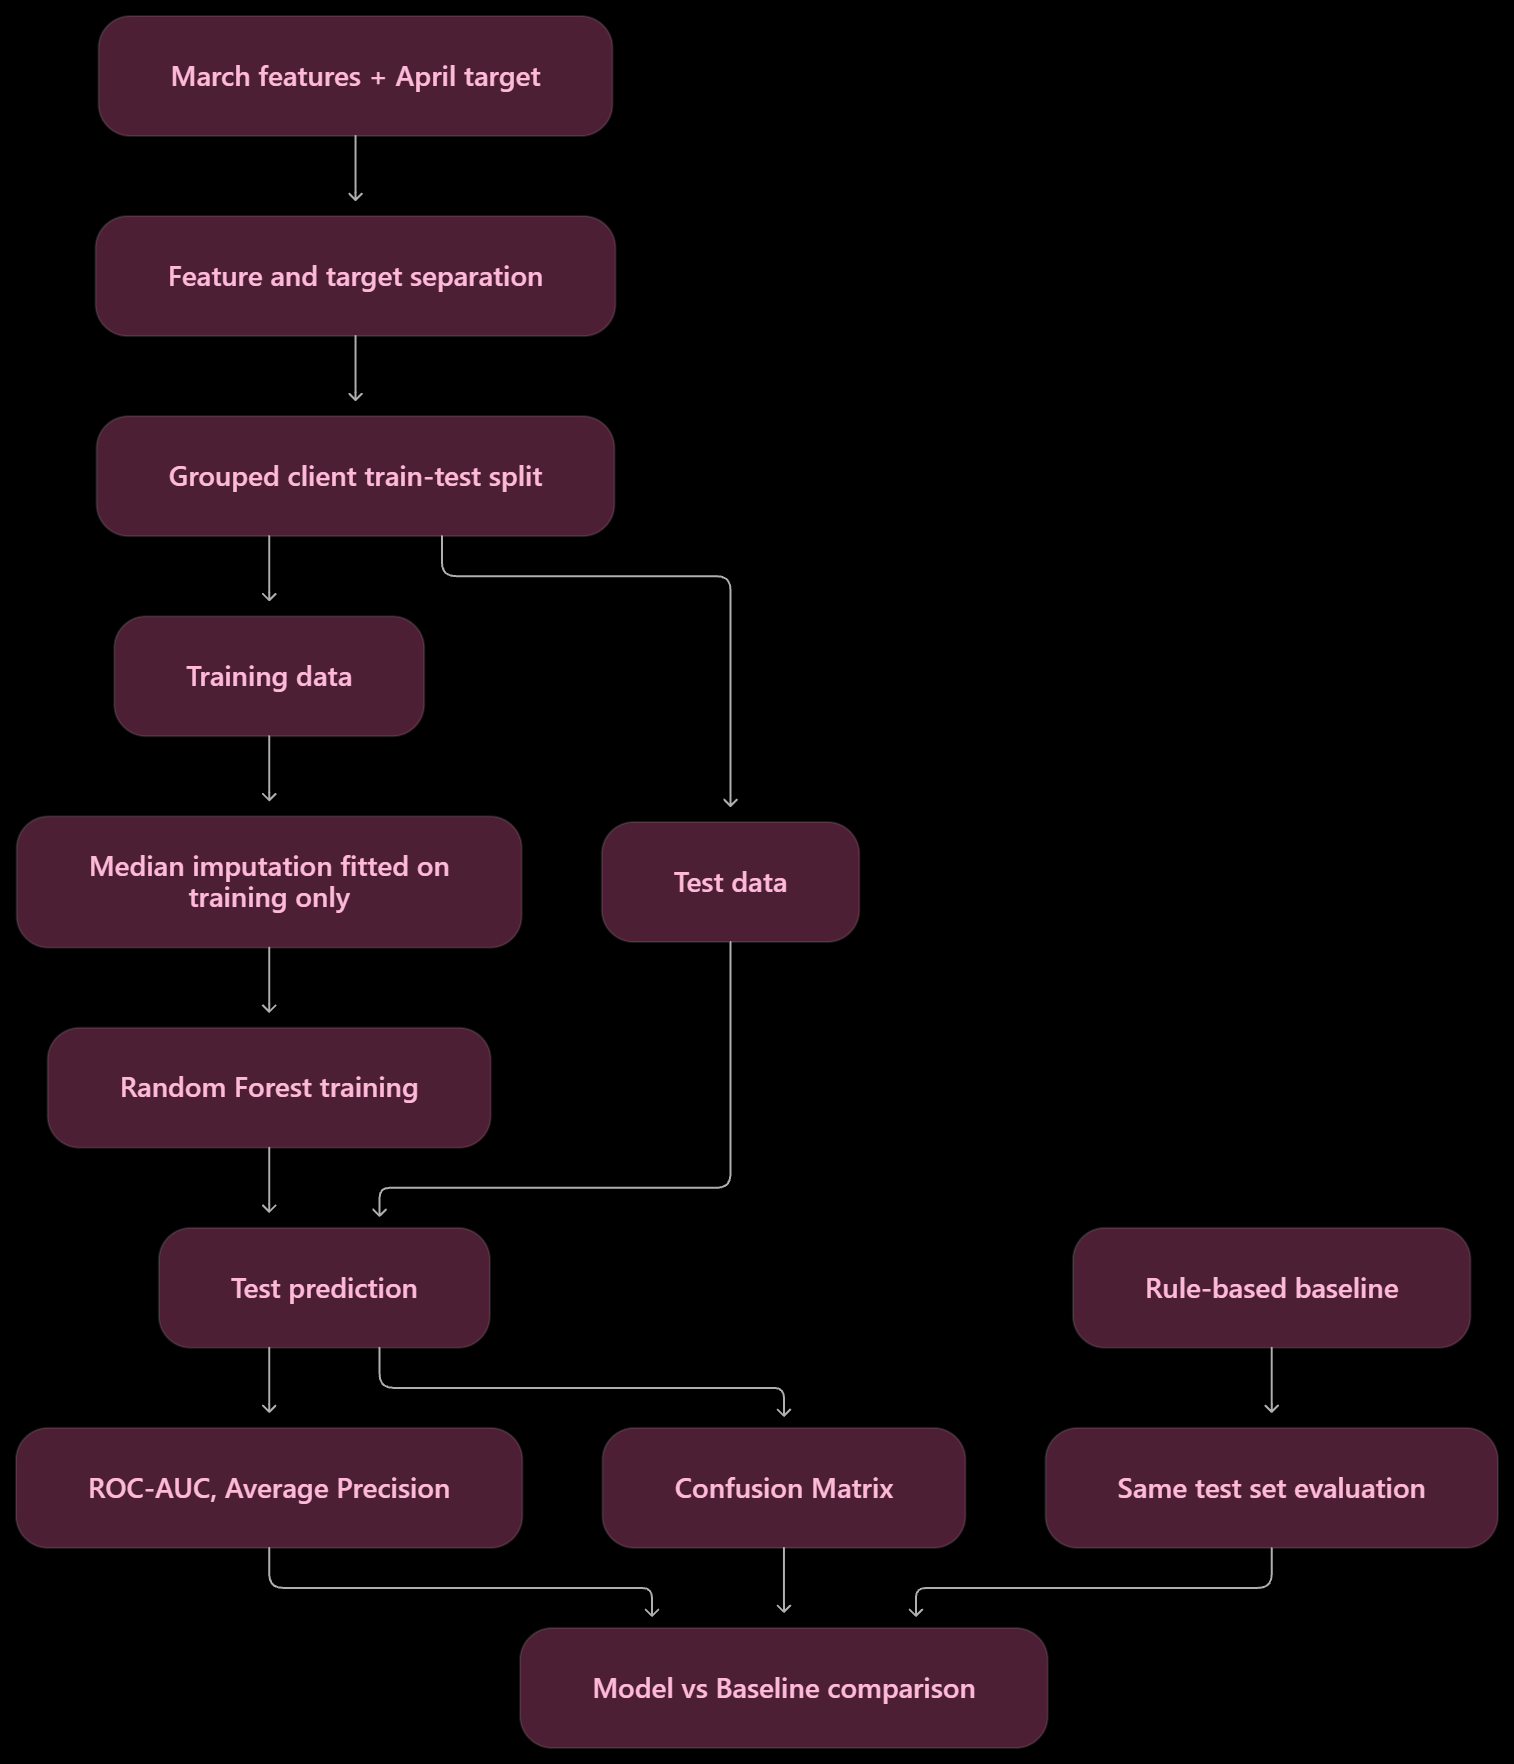



### 3.1 Feature and Target Definition

The model uses six historical performance features from March 2026: GSC impressions, GSC clicks, March CTR, average search position, GA4 pageviews, and GA4 engaged sessions.

The binary target, `future_opportunity`, is derived from April 2026 outcomes. A client-content pair is labeled positive when April impressions exceed 100 and April CTR is below 0.001.

### 3.2 Baseline

A rule-based baseline score is used as a reference for evaluating the machine learning model.

The baseline combines percentile-based visibility, CTR opportunity, and search-position opportunity signals. Its purpose is to provide a transparent heuristic comparison rather than a learned predictive model.

### 3.3 Machine Learning Model

A Random Forest classifier is used to identify client-content pairs associated with the predefined future opportunity condition.

The model uses class weighting to account for the imbalanced target distribution.

### 3.4 Validation Design

A grouped train-test split is performed using client identifiers to prevent the same client from appearing in both training and test sets.

The split uses a test size of 20% and random state 42. Model preprocessing is performed using a median imputer fitted only on the training data.

### 3.5 Evaluation Metrics

The model and baseline are evaluated on the same held-out test set using:

- ROC-AUC to assess the model's ability to distinguish positive and negative observations.
- Average Precision to evaluate positive-class ranking performance under class imbalance.
- Confusion matrix to inspect classification errors at the selected threshold.

The evaluation measures predictive performance for the predefined proxy label, not the causal impact of content refresh.


In [ ]:
# ==========================================
# 3. METHODOLOGY: FEATURE-TARGET SPLIT
# ==========================================

from sklearn.model_selection import GroupShuffleSplit

X = model_df[FEATURE_COLUMNS].copy()
y = model_df[TARGET_COLUMN].copy()
groups = model_df["client_hash_id"].copy()

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("Unique clients:", groups.nunique())

# Grouped split by client
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

# Client overlap check
train_clients = set(groups_train.unique())
test_clients = set(groups_test.unique())

client_overlap = train_clients.intersection(test_clients)

print("\nGROUPED SPLIT SUMMARY")
print("=" * 45)
print("Training rows:", f"{len(X_train):,}")
print("Testing rows:", f"{len(X_test):,}")
print("Training clients:", len(train_clients))
print("Testing clients:", len(test_clients))
print("Client overlap:", len(client_overlap))

assert len(client_overlap) == 0
assert set(X_train.columns) == set(FEATURE_COLUMNS)
assert TARGET_COLUMN not in X_train.columns

print("\nGrouped split validation: PASS")

Feature matrix: (331436, 6)
Target vector: (331436,)
Unique clients: 55

GROUPED SPLIT SUMMARY
Training rows: 300,879
Testing rows: 30,557
Training clients: 44
Testing clients: 11
Client overlap: 0

Grouped split validation: PASS


In [ ]:
# ==========================================
# PREPROCESSING AND RANDOM FOREST PIPELINE
# ==========================================

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed.")
print("Preprocessing: median imputation")
print("Imputer fitted on training data only.")
print("Classifier: Random Forest")
print("\nModel training: PASS")

Random Forest training completed.
Preprocessing: median imputation
Imputer fitted on training data only.
Classifier: Random Forest

Model training: PASS


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Use only March features from the held-out test set
baseline_test = X_test.copy()

# 1. Visibility score: higher impressions = higher visibility
visibility_score = baseline_test["gsc_impressions"].rank(pct=True)

# 2. CTR opportunity: lower CTR = higher opportunity
ctr_opportunity = 1 - baseline_test["march_ctr"].rank(pct=True)

# 3. Position opportunity: worse positive position = higher opportunity
position_opportunity = pd.Series(
    0.0,
    index=baseline_test.index
)

valid_position = baseline_test["gsc_avg_position"].notna() & (
    baseline_test["gsc_avg_position"] > 0
)

position_opportunity.loc[valid_position] = (
    1 - baseline_test.loc[
        valid_position, "gsc_avg_position"
    ].rank(pct=True)
)

# Combine the three components
baseline_score_test = (
    visibility_score +
    ctr_opportunity +
    position_opportunity
) / 3

print("BASELINE SCORE SUMMARY")
print("=" * 45)
print(baseline_score_test.describe())

assert baseline_score_test.notna().all()
assert len(baseline_score_test) == len(y_test)

print("\nBaseline score validation: PASS")

BASELINE SCORE SUMMARY
count    30557.000000
mean         0.425085
std          0.154918
min          0.153931
25%          0.276216
50%          0.403614
75%          0.561607
max          0.856980
dtype: float64

Baseline score validation: PASS


In [ ]:
# Random Forest probability scores
rf_score_test = rf_pipeline.predict_proba(X_test)[:, 1]

# Evaluate on the same held-out test set
baseline_roc_auc = roc_auc_score(
    y_test, baseline_score_test
)
baseline_ap = average_precision_score(
    y_test, baseline_score_test
)

rf_roc_auc = roc_auc_score(
    y_test, rf_score_test
)
rf_ap = average_precision_score(
    y_test, rf_score_test
)

comparison_df = pd.DataFrame({
    "Model": ["Rule-Based Baseline", "Random Forest"],
    "ROC-AUC": [baseline_roc_auc, rf_roc_auc],
    "Average Precision": [baseline_ap, rf_ap]
})

print("MODEL PERFORMANCE COMPARISON")
print("=" * 55)
display(comparison_df)

print("\nPerformance differences (RF - Baseline)")
print(f"ROC-AUC improvement: {rf_roc_auc - baseline_roc_auc:.6f}")
print(f"AP improvement:      {rf_ap - baseline_ap:.6f}")

MODEL PERFORMANCE COMPARISON


,Model,ROC-AUC,Average Precision
0,Rule-Based Baseline,0.738707,0.318966
1,Random Forest,0.921432,0.680600



Performance differences (RF - Baseline)
ROC-AUC improvement: 0.182725
AP improvement:      0.361634


### Baseline and Model Performance Comparison

The Random Forest model outperformed the rule-based baseline on both evaluation metrics using the same grouped test set of 30,557 client-content pairs.

The rule-based baseline achieved a ROC-AUC of 0.738707 and an Average Precision of 0.318966. Meanwhile, the Random Forest model achieved a ROC-AUC of 0.921432 and an Average Precision of 0.680600.

Compared with the baseline, the Random Forest model improved ROC-AUC by 0.182725 and Average Precision by 0.361634. These results indicate that the Random Forest model provides stronger discrimination and ranking performance for identifying client-content pairs that meet the defined future opportunity proxy.

However, the results should be interpreted within the scope of the March–April observation window and the proxy target definition. They do not establish causal improvements in Google Search rankings or guarantee the effectiveness of future content refresh actions.

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict using threshold 0.5
rf_predictions = (rf_score_test >= 0.5).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, rf_predictions)
precision = precision_score(y_test, rf_predictions, zero_division=0)
recall = recall_score(y_test, rf_predictions, zero_division=0)
f1 = f1_score(y_test, rf_predictions, zero_division=0)

print("RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 55)
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["No Opportunity", "Future Opportunity"],
    zero_division=0
))

print("OVERALL METRICS")
print("=" * 55)
print(f"Accuracy : {accuracy:.6f}")
print(f"Precision: {precision:.6f}")
print(f"Recall   : {recall:.6f}")
print(f"F1-score : {f1:.6f}")

RANDOM FOREST CLASSIFICATION REPORT
                    precision    recall  f1-score   support

    No Opportunity       0.98      0.81      0.89     25247
Future Opportunity       0.51      0.93      0.66      5310

          accuracy                           0.83     30557
         macro avg       0.75      0.87      0.77     30557
      weighted avg       0.90      0.83      0.85     30557

OVERALL METRICS
Accuracy : 0.832379
Precision: 0.509681
Recall   : 0.932015
F1-score : 0.658988


### Classification Performance Analysis

At a classification threshold of 0.5, the Random Forest model achieved an accuracy of 0.832379 and an F1-score of 0.658988. The model obtained a precision of 0.509681 and a recall of 0.932015 for the Future Opportunity class.

The high recall indicates that the model successfully identifies most client-content pairs that meet the defined future opportunity proxy. However, the relatively lower precision indicates that a considerable number of predicted positive cases do not meet the target condition.

For this project, the model is therefore positioned as a prioritization tool to support human review rather than an autonomous decision-making system. The classification threshold may also be considered in future work to balance the number of opportunities identified against the review workload.

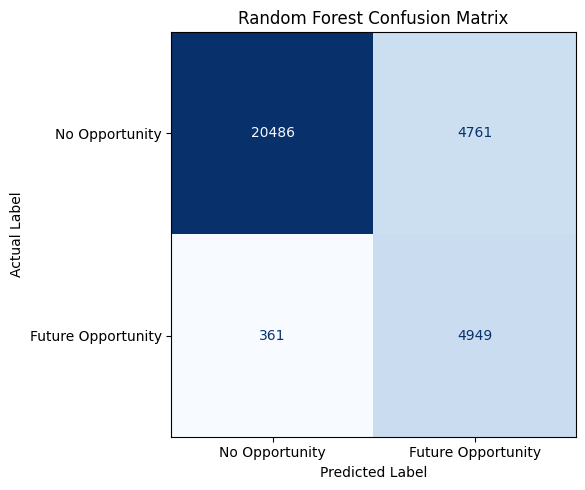

CONFUSION MATRIX SUMMARY
True Negative : 20,486
False Positive: 4,761
False Negative: 361
True Positive : 4,949


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, rf_predictions)

fig, ax = plt.subplots(figsize=(7, 5))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Opportunity", "Future Opportunity"]
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Random Forest Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("CONFUSION MATRIX SUMMARY")
print("=" * 45)
print(f"True Negative : {tn:,}")
print(f"False Positive: {fp:,}")
print(f"False Negative: {fn:,}")
print(f"True Positive : {tp:,}")

### Confusion Matrix Analysis

The confusion matrix shows that the Random Forest model correctly classified 20,486 negative cases (True Negatives) and 4,949 positive cases (True Positives). However, it also produced 4,761 False Positives and 361 False Negatives.

The relatively small number of False Negatives is consistent with the model's high recall of 0.932015, indicating that most cases meeting the future opportunity proxy were successfully identified. Nevertheless, the False Positive count indicates that some cases would require additional human review.

These findings support using the model as a decision-support and prioritization tool, with human verification before any content-related action is taken.

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
0,gsc_impressions,0.618917
1,gsc_avg_position,0.179190
2,march_ctr,0.102720
3,gsc_clicks,0.069861
4,ga4_pageviews,0.026835
5,ga4_engaged_sessions,0.002477


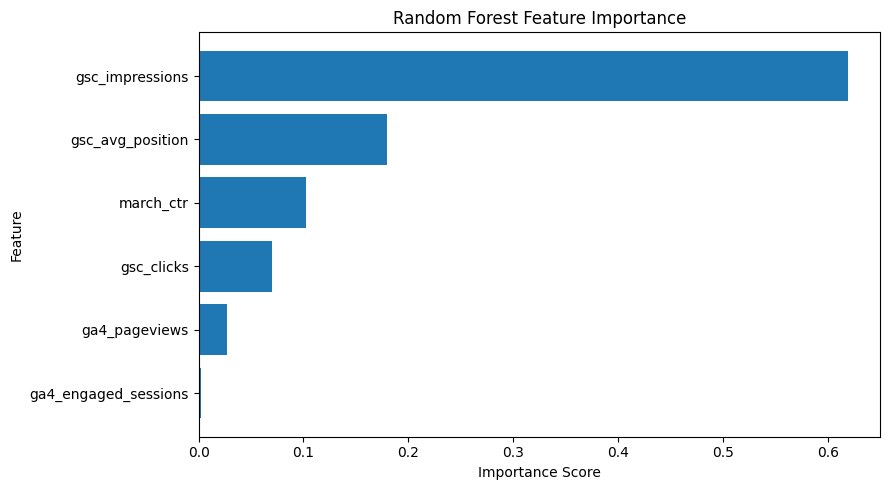


Feature importance validation: PASS


In [ ]:
# Extract the trained Random Forest model from the pipeline
rf_model = rf_pipeline.named_steps["classifier"]

# Create feature importance table
feature_importance_df = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 50)
display(feature_importance_df)

# Visualize feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

assert len(feature_importance_df) == len(FEATURE_COLUMNS)
assert np.isclose(feature_importance_df["Importance"].sum(), 1.0)

print("\nFeature importance validation: PASS")

### Feature Importance Analysis

The feature importance analysis indicates that `gsc_impressions` is the most influential feature in the Random Forest model, with an importance score of 0.618917 (61.89%). It is followed by `gsc_avg_position` at 0.179190 (17.92%) and `march_ctr` at 0.102720 (10.27%).

The three most influential features account for approximately 90.08% of the model's total feature importance. This suggests that search visibility and click-through performance signals contribute substantially to the model's predictive decisions.

In comparison, `ga4_pageviews` and `ga4_engaged_sessions` have relatively small importance scores of 0.026835 and 0.002477, respectively.

These values represent the relative contribution of each feature within the trained Random Forest model. They do not establish causal relationships or indicate the direction of each feature's effect on predictions.

In [ ]:
# SECTION 3: METHODOLOGY VALIDATION

assert len(X_train) == 300_879
assert len(X_test) == 30_557
assert len(client_overlap) == 0

assert isinstance(rf_pipeline, Pipeline)
assert rf_pipeline.named_steps["imputer"].strategy == "median"

assert len(comparison_df) == 2
assert rf_roc_auc > baseline_roc_auc
assert rf_ap > baseline_ap

assert len(feature_importance_df) == 6
assert np.isclose(
    feature_importance_df["Importance"].sum(), 1.0
)

assert cm.shape == (2, 2)
assert tn + fp + fn + tp == len(y_test)

print("SECTION 3 METHODOLOGY VALIDATION")
print("=" * 50)
print("Grouped split: PASS")
print("Client leakage check: PASS")
print("Training-only imputation: PASS")
print("Baseline comparison: PASS")
print("Classification evaluation: PASS")
print("Feature importance: PASS")
print("Confusion matrix: PASS")

print("\nSection 3: COMPLETE")

SECTION 3 METHODOLOGY VALIDATION
Grouped split: PASS
Client leakage check: PASS
Training-only imputation: PASS
Baseline comparison: PASS
Classification evaluation: PASS
Feature importance: PASS
Confusion matrix: PASS

Section 3: COMPLETE


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

# 4. Results

This section presents the experimental results of the rule-based baseline and Random Forest model for identifying client-content pairs that meet the defined future opportunity proxy.

The evaluation was conducted using a grouped train-test split based on client identifiers, resulting in 300,879 training rows and 30,557 testing rows. The model was evaluated using ROC-AUC, Average Precision, accuracy, precision, recall, and F1-score.

The results also include a confusion matrix analysis and feature importance assessment to examine classification performance and identify the main signals contributing to the model's predictions.

In [ ]:
# SECTION 4: EXPERIMENTAL RESULTS SUMMARY

results_summary = pd.DataFrame([
    {
        "Experiment": "Rule-Based Baseline",
        "ROC-AUC": baseline_roc_auc,
        "Average Precision": baseline_ap,
        "Accuracy": np.nan,
        "Precision": np.nan,
        "Recall": np.nan,
        "F1-score": np.nan
    },
    {
        "Experiment": "Random Forest",
        "ROC-AUC": rf_roc_auc,
        "Average Precision": rf_ap,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }
])

print("EXPERIMENTAL RESULTS SUMMARY")
print("=" * 70)

display(
    results_summary.round(6)
)

print("\nResults summary validation: PASS")

EXPERIMENTAL RESULTS SUMMARY


,Experiment,ROC-AUC,Average Precision,Accuracy,Precision,Recall,F1-score
0,Rule-Based Baseline,0.738707,0.318966,NaN,NaN,NaN,NaN
1,Random Forest,0.921432,0.680600,0.832379,0.509681,0.932015,0.658988



Results summary validation: PASS


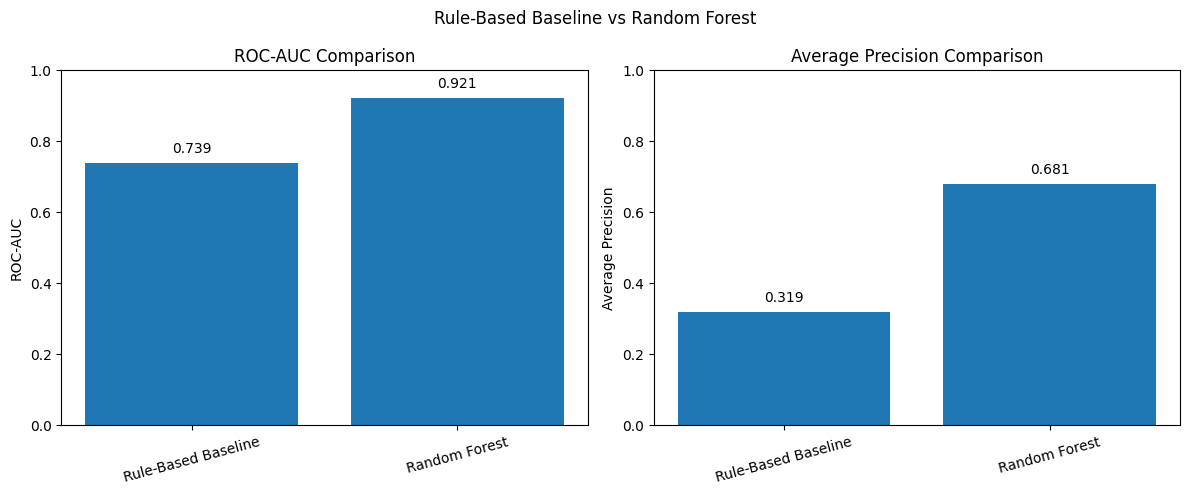

Performance visualization: COMPLETE


In [ ]:
# SECTION 4: MODEL PERFORMANCE VISUALIZATION

metrics_to_plot = ["ROC-AUC", "Average Precision"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = results_summary["Experiment"].tolist()

for ax, metric in zip(axes, metrics_to_plot):
    values = results_summary[metric].values

    bars = ax.bar(
        models,
        values
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.02,
            f"{value:.3f}",
            ha="center",
            va="bottom"
        )

plt.suptitle("Rule-Based Baseline vs Random Forest")
plt.tight_layout()
plt.show()

print("Performance visualization: COMPLETE")

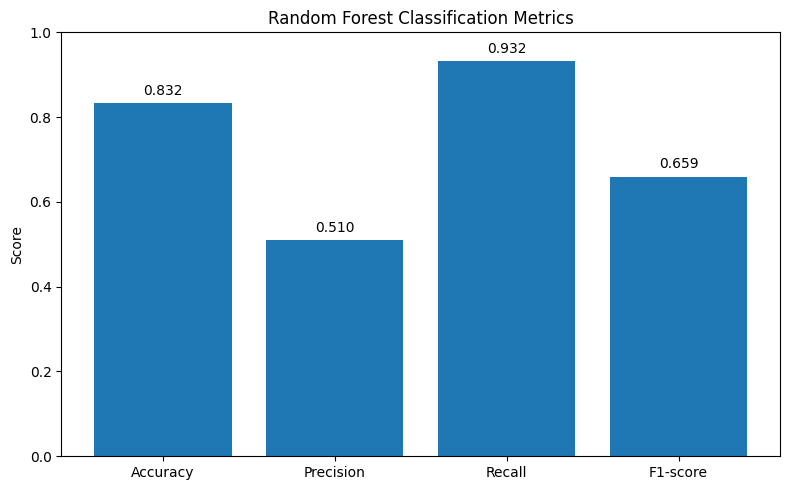

Classification metrics visualization: COMPLETE


In [ ]:
# RANDOM FOREST CLASSIFICATION METRICS

classification_metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    classification_metrics.keys(),
    classification_metrics.values()
)

plt.title("Random Forest Classification Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

for bar, value in zip(bars, classification_metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

print("Classification metrics visualization: COMPLETE")

### 4.1 Model Performance Comparison

The experimental results demonstrate that the Random Forest model outperformed the rule-based baseline in identifying client-content pairs that meet the defined future opportunity proxy. The baseline achieved a ROC-AUC of 0.738707 and an Average Precision of 0.318966, while the Random Forest model achieved 0.921432 and 0.680600, respectively.

The Random Forest model also achieved an accuracy of 0.832379, precision of 0.509681, recall of 0.932015, and F1-score of 0.658988 at a classification threshold of 0.5. The high recall indicates that the model identified most positive cases, although its moderate precision suggests that some predicted opportunities require further verification.

### 4.2 Feature Importance

The feature importance analysis identified `gsc_impressions` as the most influential feature, contributing 0.618917 of the total importance. The next most influential features were `gsc_avg_position` (0.179190) and `march_ctr` (0.102720).

These findings suggest that search visibility and click-through performance signals play a substantial role in the model's predictive decisions. However, feature importance represents model-level contribution and does not establish causal relationships.

### 4.3 Overall Findings

Overall, the Random Forest model provides stronger predictive and ranking performance than the rule-based baseline on the grouped test set. The results support its use as a decision-support mechanism for prioritizing client-content pairs for human review. The model should not be interpreted as a guarantee of improved Google Search rankings or content performance.

## 5. Limitations

*What this work cannot claim.*

# 5. Limitations

Despite the promising experimental results, several limitations should be considered when interpreting the findings.

**1. Proxy Target Definition**

The `future_opportunity` target was defined using April search performance data, specifically impressions greater than 100 and CTR below 0.001. This target represents a proxy condition rather than verified evidence that a content page requires refreshing or will benefit from optimization.

**2. Limited Temporal Evaluation**

The experiment used March 2026 data as input features and April 2026 data as the outcome window. Therefore, the model has not been evaluated across multiple temporal windows. Its performance may differ under other periods or changing search conditions.

**3. Missing Search Position Data**

The `gsc_avg_position` feature contains 154,699 missing values, representing approximately 46.68% of the modeling dataset. Median imputation was applied through a training-only preprocessing pipeline. Although this prevents preprocessing leakage, imputation may not fully represent the unavailable search position information.

**4. Class Imbalance**

The target distribution consists of 280,002 negative cases (84.48%) and 51,434 positive cases (15.52%). This imbalance may affect classification behavior and makes accuracy alone insufficient for evaluating model performance. ROC-AUC, Average Precision, precision, recall, and F1-score were therefore also considered.

**5. False Positive Predictions and Human Verification**

At a classification threshold of 0.5, the model produced 4,761 false positives and 361 false negatives. Consequently, some predicted opportunities do not satisfy the defined target condition. The model should therefore support human review rather than automatically trigger content changes.

**6. Evaluation Scope**

The evaluation focused on ROC-AUC, Average Precision, and threshold-based classification metrics. Although ranking-oriented evaluation was initially considered, NDCG was not calculated in the final experiment. Further evaluation using ranking-specific metrics and additional temporal validation would strengthen the assessment.

Overall, these limitations indicate that the proposed model should be interpreted as a decision-support approach for prioritizing client-content pairs based on observed search and content performance signals. The findings do not establish causal effects on search rankings or guarantee improvements from content refresh actions.

In [ ]:
# SECTION 5: LIMITATIONS VALIDATION

total_rows = len(model_df)

missing_position = model_df["gsc_avg_position"].isna().sum()
missing_position_pct = missing_position / total_rows * 100

target_counts = model_df[TARGET_COLUMN].value_counts()
negative_count = int(target_counts[0])
positive_count = int(target_counts[1])

negative_pct = negative_count / total_rows * 100
positive_pct = positive_count / total_rows * 100

print("LIMITATIONS DATA VALIDATION")
print("=" * 55)

print(f"Modeling rows              : {total_rows:,}")
print(
    f"Missing gsc_avg_position   : "
    f"{missing_position:,} ({missing_position_pct:.2f}%)"
)
print(
    f"Negative target            : "
    f"{negative_count:,} ({negative_pct:.2f}%)"
)
print(
    f"Positive target            : "
    f"{positive_count:,} ({positive_pct:.2f}%)"
)

print(f"False positives             : {fp:,}")
print(f"False negatives             : {fn:,}")

assert total_rows == 331_436
assert missing_position == 154_699
assert negative_count == 280_002
assert positive_count == 51_434
assert fp == 4_761
assert fn == 361

print("\nSection 5 numerical validation: PASS")

LIMITATIONS DATA VALIDATION
Modeling rows              : 331,436
Missing gsc_avg_position   : 154,699 (46.68%)
Negative target            : 280,002 (84.48%)
Positive target            : 51,434 (15.52%)
False positives             : 4,761
False negatives             : 361

Section 5 numerical validation: PASS


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [ ]:
# SECTION 6: TRAIN FINAL MODEL FOR RANKED RECOMMENDATIONS

X_full = model_df[FEATURE_COLUMNS].copy()
y_full = model_df[TARGET_COLUMN].copy()

final_rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

final_rf_pipeline.fit(X_full, y_full)

print("FINAL MODEL TRAINING")
print("=" * 50)
print(f"Training rows: {len(X_full):,}")
print(f"Features: {len(FEATURE_COLUMNS)}")
print("Model: Random Forest")
print("Preprocessing: Median imputation")
print("Training scope: Full March-April labeled dataset")

print("\nFinal model training: PASS")

FINAL MODEL TRAINING
Training rows: 331,436
Features: 6
Model: Random Forest
Preprocessing: Median imputation
Training scope: Full March-April labeled dataset

Final model training: PASS


In [ ]:
# SECTION 6: GENERATE MODEL SCORES AND RANKING

# Predict probability of Future Opportunity
model_scores = final_rf_pipeline.predict_proba(X_full)[:, 1]

# Build initial recommendation queue
ranked_queue = model_df[JOIN_KEYS + FEATURE_COLUMNS].copy()

ranked_queue["model_score"] = model_scores

# Sort by model score descending
# Use impressions as tie-breaker
ranked_queue = ranked_queue.sort_values(
    by=["model_score", "gsc_impressions"],
    ascending=[False, False]
).reset_index(drop=True)

# Assign ranking
ranked_queue["rank"] = np.arange(1, len(ranked_queue) + 1)

print("RANKED QUEUE SUMMARY")
print("=" * 50)
print(f"Queue rows: {len(ranked_queue):,}")
print(f"Unique client-content pairs: {ranked_queue[JOIN_KEYS].drop_duplicates().shape[0]:,}")

print("\nModel score distribution:")
display(ranked_queue["model_score"].describe())

print("\nTOP 20 RANKED CONTENT PAIRS")
display(
    ranked_queue[
        ["rank"] + JOIN_KEYS + [
            "model_score",
            "gsc_impressions",
            "gsc_clicks",
            "march_ctr",
            "gsc_avg_position"
        ]
    ].head(20)
)

assert len(ranked_queue) == 331_436
assert ranked_queue[JOIN_KEYS].drop_duplicates().shape[0] == 331_436
assert ranked_queue["model_score"].between(0, 1).all()
assert ranked_queue["rank"].is_unique

print("\nRanked queue validation: PASS")

RANKED QUEUE SUMMARY
Queue rows: 331,436
Unique client-content pairs: 331,436

Model score distribution:


,model_score
count,331436.000000
mean,0.300017
std,0.327643
min,0.002201
25%,0.065720
50%,0.065720
75%,0.600349
max,0.989498



TOP 20 RANKED CONTENT PAIRS


,rank,client_hash_id,content_hash_id,model_score,gsc_impressions,gsc_clicks,march_ctr,gsc_avg_position
0,1,client_23a62021009f63c4,content_b77c09e114e0ed4c,0.989498,47736,4,0.000084,36.305198
1,2,client_23a62021009f63c4,content_b63094bd417908e9,0.989319,25524,2,0.000078,42.840013
2,3,client_23a62021009f63c4,content_6305299bf66fcfc1,0.988712,13086,2,0.000153,42.983573
3,4,client_23a62021009f63c4,content_e15824af3c396214,0.988677,30196,2,0.000066,47.602550
4,5,client_e547b89c05043229,content_e986eb3ab70fcee6,0.988570,25711,6,0.000233,29.844970
5,6,client_23a62021009f63c4,content_4ee39f5889ebcee2,0.988459,27683,4,0.000144,39.680649
6,7,client_23a62021009f63c4,content_343790fb8e17cfbf,0.988422,19653,2,0.000102,35.318523
7,8,client_23a62021009f63c4,content_4abfb7ddc8438eb8,0.988209,26981,5,0.000185,31.461736
8,9,client_23a62021009f63c4,content_9c267e93694b0a37,0.988108,20470,3,0.000147,31.160639
9,10,client_23a62021009f63c4,content_0c9e08e28fbd22ed,0.988097,16276,3,0.000184,35.553493



Ranked queue validation: PASS


In [ ]:
# SECTION 6: REASON CODES AND RECOMMENDED ACTIONS

# Initialize default reason code
ranked_queue["reason_code"] = "REVIEW"

# Rule 1: High impressions with low CTR
high_impressions_low_ctr = (
    (ranked_queue["gsc_impressions"] > 100) &
    (ranked_queue["march_ctr"] < 0.001)
)

ranked_queue.loc[
    high_impressions_low_ctr,
    "reason_code"
] = "HIGH_IMPRESSIONS_LOW_CTR"

# Rule 2: Good position with low CTR
good_position_low_ctr = (
    (ranked_queue["gsc_avg_position"] > 0) &
    (ranked_queue["gsc_avg_position"] <= 10) &
    (ranked_queue["march_ctr"] < 0.001)
)

ranked_queue.loc[
    good_position_low_ctr &
    (ranked_queue["reason_code"] == "REVIEW"),
    "reason_code"
] = "GOOD_POSITION_LOW_CTR"

# Rule 3: High visibility
high_visibility = ranked_queue["gsc_impressions"] > 100

ranked_queue.loc[
    high_visibility &
    (ranked_queue["reason_code"] == "REVIEW"),
    "reason_code"
] = "HIGH_VISIBILITY"

# Map reason codes to recommended actions
action_mapping = {
    "HIGH_IMPRESSIONS_LOW_CTR": "REVIEW_CTR",
    "GOOD_POSITION_LOW_CTR": "REVIEW_CTR",
    "HIGH_VISIBILITY": "REVIEW",
    "REVIEW": "NO_ACTION"
}

ranked_queue["recommended_action"] = (
    ranked_queue["reason_code"].map(action_mapping)
)

# Add human-readable explanations
reason_text_mapping = {
    "HIGH_IMPRESSIONS_LOW_CTR":
        "High search visibility with low March CTR; review search snippet relevance and content alignment.",
    "GOOD_POSITION_LOW_CTR":
        "Relatively good search position with low March CTR; review title and meta description relevance.",
    "HIGH_VISIBILITY":
        "High search visibility; review content performance and engagement signals.",
    "REVIEW":
        "No specific rule-based opportunity signal identified; no immediate action recommended."
}

ranked_queue["reason_text"] = (
    ranked_queue["reason_code"].map(reason_text_mapping)
)

print("REASON CODE DISTRIBUTION")
print("=" * 50)
display(ranked_queue["reason_code"].value_counts())

print("\nRECOMMENDED ACTION DISTRIBUTION")
print("=" * 50)
display(ranked_queue["recommended_action"].value_counts())

print("\nTOP 20 RANKED ACTIONS")
display(
    ranked_queue[
        [
            "rank",
            "model_score",
            "reason_code",
            "reason_text",
            "recommended_action",
            "gsc_impressions",
            "march_ctr",
            "gsc_avg_position"
        ]
    ].head(20)
)

assert ranked_queue["reason_code"].notna().all()
assert ranked_queue["recommended_action"].notna().all()
assert ranked_queue["reason_text"].notna().all()

print("\nReason code validation: PASS")

REASON CODE DISTRIBUTION


,count
reason_code,
REVIEW,191301
HIGH_VISIBILITY,53977
HIGH_IMPRESSIONS_LOW_CTR,47255
GOOD_POSITION_LOW_CTR,38903



RECOMMENDED ACTION DISTRIBUTION


,count
recommended_action,
NO_ACTION,191301
REVIEW_CTR,86158
REVIEW,53977



TOP 20 RANKED ACTIONS


,rank,model_score,reason_code,reason_text,recommended_action,gsc_impressions,march_ctr,gsc_avg_position
0,1,0.989498,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,47736,0.000084,36.305198
1,2,0.989319,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,25524,0.000078,42.840013
2,3,0.988712,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,13086,0.000153,42.983573
3,4,0.988677,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,30196,0.000066,47.602550
4,5,0.988570,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,25711,0.000233,29.844970
5,6,0.988459,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,27683,0.000144,39.680649
6,7,0.988422,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,19653,0.000102,35.318523
7,8,0.988209,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,26981,0.000185,31.461736
8,9,0.988108,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,20470,0.000147,31.160639
9,10,0.988097,HIGH_IMPRESSIONS_LOW_CTR,High search visibility with low March CTR; rev...,REVIEW_CTR,16276,0.000184,35.553493



Reason code validation: PASS


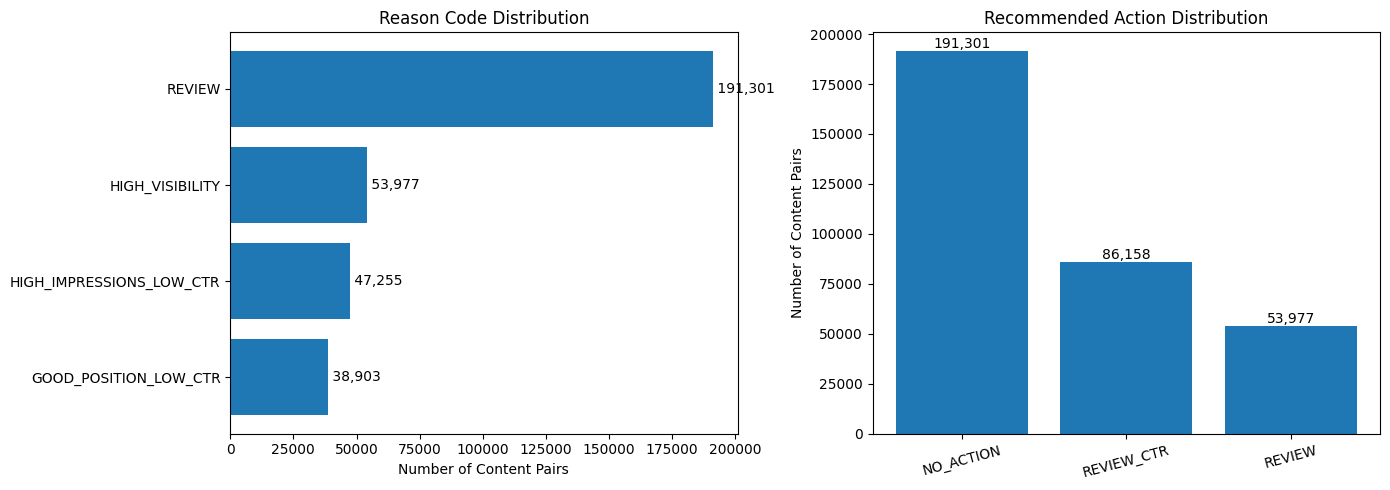

Action queue visualization: COMPLETE


In [ ]:
# SECTION 6: ACTION QUEUE VISUALIZATION

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Reason code distribution
reason_counts = ranked_queue["reason_code"].value_counts()

axes[0].barh(
    reason_counts.index,
    reason_counts.values
)
axes[0].set_title("Reason Code Distribution")
axes[0].set_xlabel("Number of Content Pairs")
axes[0].invert_yaxis()

for i, value in enumerate(reason_counts.values):
    axes[0].text(value, i, f" {value:,}", va="center")

# Recommended action distribution
action_counts = ranked_queue["recommended_action"].value_counts()

axes[1].bar(
    action_counts.index,
    action_counts.values
)
axes[1].set_title("Recommended Action Distribution")
axes[1].set_ylabel("Number of Content Pairs")
axes[1].tick_params(axis="x", rotation=15)

for bar, value in zip(axes[1].patches, action_counts.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("Action queue visualization: COMPLETE")

In [ ]:
# SECTION 6: FINAL VALIDATION

assert len(ranked_queue) == 331_436
assert ranked_queue["rank"].min() == 1
assert ranked_queue["rank"].max() == 331_436
assert ranked_queue["rank"].is_unique

assert ranked_queue["model_score"].between(0, 1).all()

assert ranked_queue["reason_code"].value_counts().to_dict() == {
    "REVIEW": 191_301,
    "HIGH_VISIBILITY": 53_977,
    "HIGH_IMPRESSIONS_LOW_CTR": 47_255,
    "GOOD_POSITION_LOW_CTR": 38_903
}

assert ranked_queue["recommended_action"].value_counts().to_dict() == {
    "NO_ACTION": 191_301,
    "REVIEW_CTR": 86_158,
    "REVIEW": 53_977
}

assert ranked_queue["reason_text"].notna().all()

print("SECTION 6 FINAL VALIDATION")
print("=" * 50)
print("Unique client-content pairs: PASS")
print("Ranking sequence: PASS")
print("Model score range: PASS")
print("Reason code distribution: PASS")
print("Recommended action distribution: PASS")
print("Reason explanations: PASS")

print("\nSection 6: COMPLETE")

SECTION 6 FINAL VALIDATION
Unique client-content pairs: PASS
Ranking sequence: PASS
Model score range: PASS
Reason code distribution: PASS
Recommended action distribution: PASS
Reason explanations: PASS

Section 6: COMPLETE


### 6.1 Interpretation of the Ranked Queue

The final Random Forest model was trained on all 331,436 available client-content pairs to generate the ranked action queue. Each pair was assigned a model score and sorted in descending order, with March impressions used as a secondary sorting criterion.

The model scores ranged from 0.002201 to 0.989498, with a median of 0.065720. These scores represent the model's estimated likelihood of the predefined future opportunity condition. They should not be interpreted as the probability that refreshing a page will improve its search performance.

The rule-based reason codes provide additional context for interpreting the queue. The most frequent reason code was `REVIEW`, covering 191,301 pairs. This was followed by `HIGH_VISIBILITY` (53,977 pairs), `HIGH_IMPRESSIONS_LOW_CTR` (47,255 pairs), and `GOOD_POSITION_LOW_CTR` (38,903 pairs).

The recommended action distribution consisted of 191,301 pairs assigned to `NO_ACTION`, 86,158 assigned to `REVIEW_CTR`, and 53,977 assigned to `REVIEW`. The `NO_ACTION` category indicates that no specific rule-based opportunity signal was identified; it does not mean that the content has been proven to perform well.

The highest-ranked candidates were primarily associated with high impressions and low click-through rates. This pattern suggests that the queue can help reviewers identify visible content with relatively low click engagement for further investigation. Potential review activities include examining title and meta description relevance, search intent alignment, and content presentation.

Overall, the ranked queue is a retrospective decision-support artifact generated using the full March-April dataset. It is not a prospective ranking produced using March data alone, and its scores do not establish that taking the recommended actions will cause improvements in search performance. Human review remains necessary before any content changes are considered.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*


This section collects the charts and tables that will be embedded in the deployed research paper.

The artifacts summarize the dataset, target distribution, model evaluation results, feature importance, and ranked recommendation outputs.

### 7.1 Charts

The following charts are prepared for the research paper:

1. Baseline vs. Random Forest Performance (ROC-AUC and Average Precision).
2. Random Forest Classification Metrics.
3. Confusion Matrix.
4. Random Forest Feature Importance.
5. Reason Code Distribution.
6. Recommended Action Distribution.

### 7.2 Tables

The following tables are prepared for the research paper:

1. Dataset Overview.
2. Target Class Distribution.
3. Model Performance Comparison.
4. Feature Importance.

### 7.3 Artifact Preparation

All charts and tables are generated from the experiment outputs documented in this notebook. Only aggregate results and privacy-safe visualizations are included in the public research paper. Client identifiers, content identifiers, raw datasets, and private records are excluded.


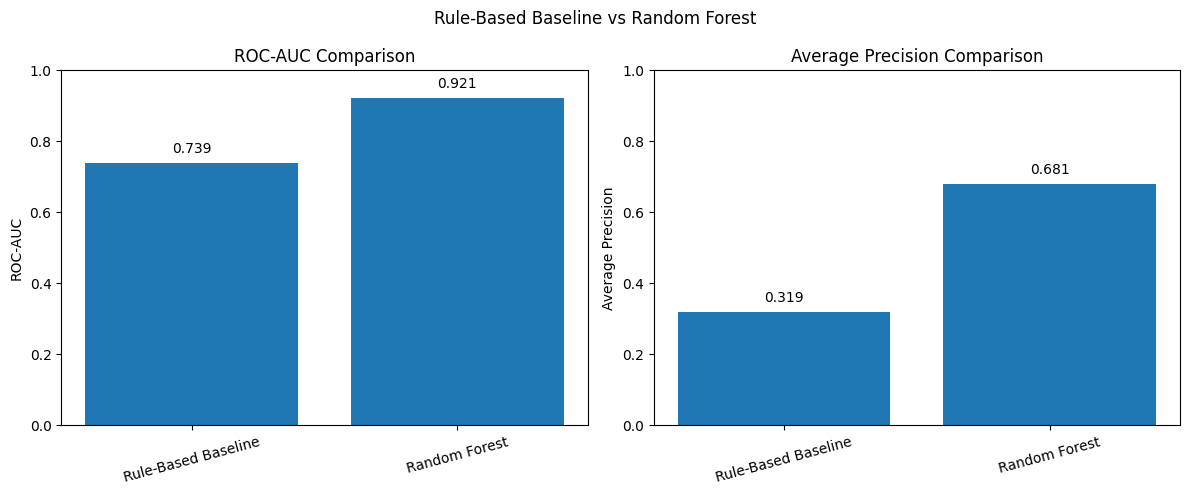

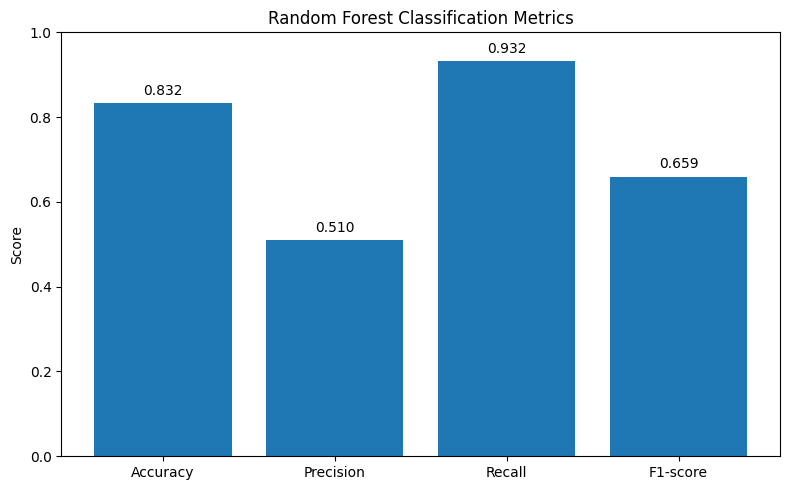

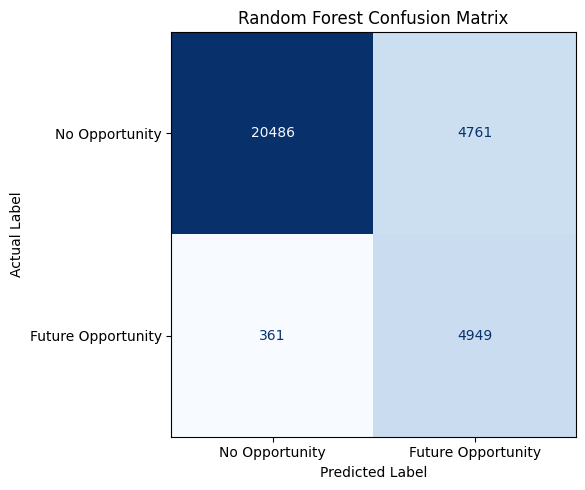

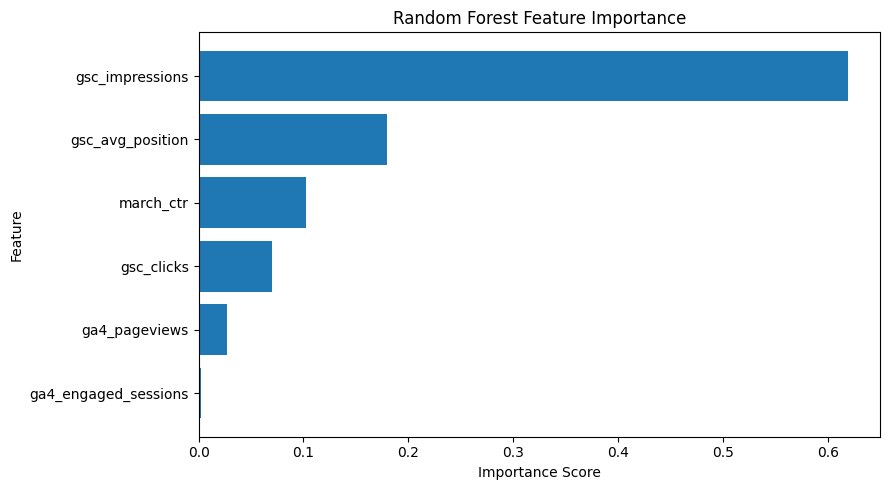

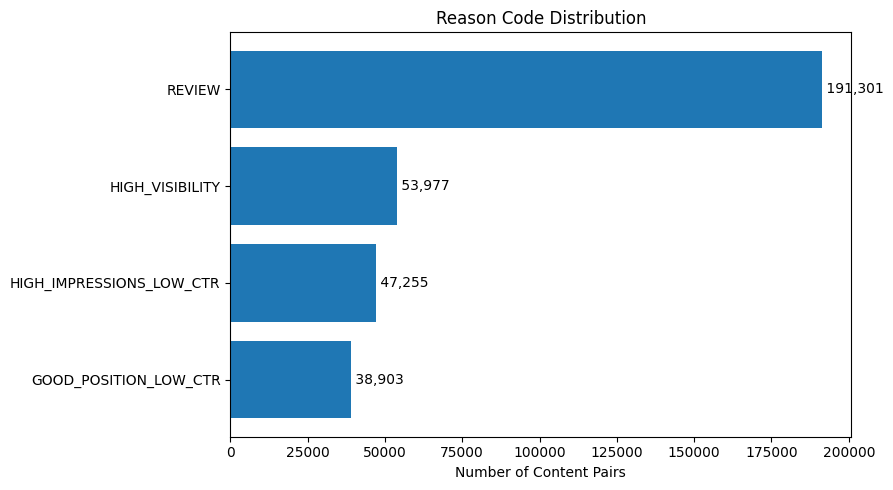

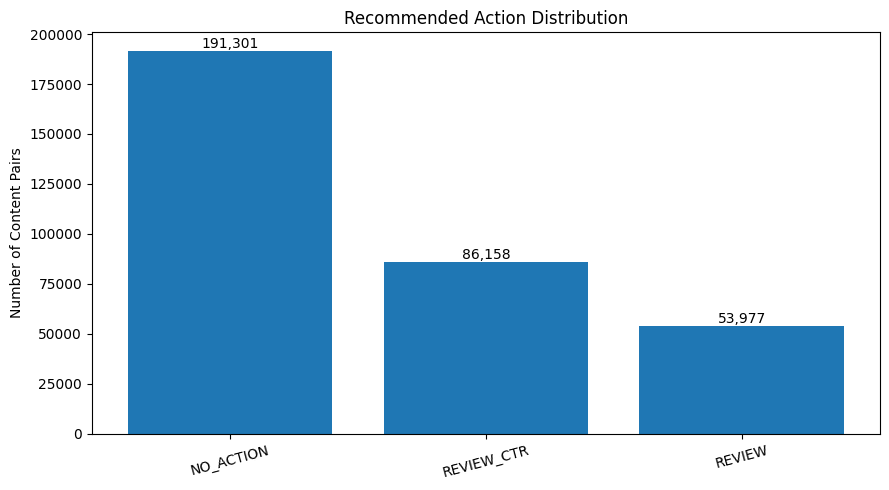


SAVED PAPER FIGURES
01_model_performance_comparison.png
02_classification_metrics.png
03_confusion_matrix.png
04_feature_importance.png
05_reason_code_distribution.png
06_recommended_action_distribution.png

Figure export validation: PASS


In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create output directory
FIGURE_DIR = "work/outputs/paper_figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

# ==========================================
# 1. BASELINE VS RANDOM FOREST PERFORMANCE
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics_to_plot = ["ROC-AUC", "Average Precision"]
models = results_summary["Experiment"].tolist()

for ax, metric in zip(axes, metrics_to_plot):
    values = results_summary[metric].values

    bars = ax.bar(models, values)

    ax.set_title(f"{metric} Comparison")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.02,
            f"{value:.3f}",
            ha="center",
            va="bottom"
        )

plt.suptitle("Rule-Based Baseline vs Random Forest")
plt.tight_layout()
plt.savefig(
    f"{FIGURE_DIR}/01_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==========================================
# 2. RANDOM FOREST CLASSIFICATION METRICS
# ==========================================

classification_metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    classification_metrics.keys(),
    classification_metrics.values()
)

plt.title("Random Forest Classification Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

for bar, value in zip(bars, classification_metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    f"{FIGURE_DIR}/02_classification_metrics.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==========================================
# 3. CONFUSION MATRIX
# ==========================================

fig, ax = plt.subplots(figsize=(7, 5))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Opportunity", "Future Opportunity"]
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Random Forest Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig(
    f"{FIGURE_DIR}/03_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==========================================
# 4. FEATURE IMPORTANCE
# ==========================================

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig(
    f"{FIGURE_DIR}/04_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==========================================
# 5. REASON CODE DISTRIBUTION
# ==========================================

reason_counts = ranked_queue["reason_code"].value_counts()

plt.figure(figsize=(9, 5))

bars = plt.barh(
    reason_counts.index,
    reason_counts.values
)

plt.title("Reason Code Distribution")
plt.xlabel("Number of Content Pairs")
plt.gca().invert_yaxis()

for bar, value in zip(bars, reason_counts.values):
    plt.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f" {value:,}",
        va="center"
    )

plt.tight_layout()
plt.savefig(
    f"{FIGURE_DIR}/05_reason_code_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==========================================
# 6. RECOMMENDED ACTION DISTRIBUTION
# ==========================================

action_counts = ranked_queue["recommended_action"].value_counts()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    action_counts.index,
    action_counts.values
)

plt.title("Recommended Action Distribution")
plt.ylabel("Number of Content Pairs")
plt.xticks(rotation=15)

for bar, value in zip(bars, action_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    f"{FIGURE_DIR}/06_recommended_action_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==========================================
# FINAL CHECK
# ==========================================

saved_figures = sorted(os.listdir(FIGURE_DIR))

print("\nSAVED PAPER FIGURES")
print("=" * 55)

for file in saved_figures:
    print(file)

assert len(saved_figures) == 6

print("\nFigure export validation: PASS")

In [ ]:
from google.colab import files
import shutil

shutil.make_archive(
    "/content/paper_figures",
    "zip",
    "/content/work/outputs/paper_figures"
)

files.download("/content/paper_figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
import numpy as np

TABLE_DIR = "work/outputs/paper_tables"
os.makedirs(TABLE_DIR, exist_ok=True)

# ==========================================
# 1. DATASET OVERVIEW
# ==========================================

dataset_overview = pd.DataFrame([
    ["Dataset", "FlyRank/internship-warehouse"],
    ["Source table", "fact_content_daily_performance"],
    ["Observation period", "March 1-31, 2026"],
    ["Outcome period", "April 1-30, 2026"],
    ["March raw records", 9_841_378],
    ["April raw records", 10_424_730],
    ["March aggregated pairs", 331_437],
    ["Final modeling pairs", 331_436],
    ["Unique client-content pairs", 331_436],
    ["Input features", 6],
    ["Missing gsc_avg_position", "46.68%"]
], columns=["Attribute", "Description"])

# ==========================================
# 2. TARGET CLASS DISTRIBUTION
# ==========================================

target_counts = y_full.value_counts().sort_index()

target_distribution = pd.DataFrame({
    "Target Class": [
        "No Opportunity",
        "Future Opportunity"
    ],
    "Count": [
        int(target_counts.loc[0]),
        int(target_counts.loc[1])
    ]
})

target_distribution["Percentage"] = (
    target_distribution["Count"] /
    target_distribution["Count"].sum() * 100
).round(2)

# ==========================================
# 3. MODEL PERFORMANCE COMPARISON
# ==========================================

model_performance = comparison_df.copy()

model_performance = model_performance.rename(
    columns={"Model": "Experiment"}
)

model_performance = model_performance.round(6)

# ==========================================
# 4. FEATURE IMPORTANCE
# ==========================================

feature_importance_table = feature_importance_df.copy()

feature_importance_table["Importance"] = (
    feature_importance_table["Importance"].round(6)
)

feature_importance_table["Importance (%)"] = (
    feature_importance_table["Importance"] * 100
).round(2)

# ==========================================
# SAVE ALL TABLES
# ==========================================

tables = {
    "01_dataset_overview.csv": dataset_overview,
    "02_target_class_distribution.csv": target_distribution,
    "03_model_performance_comparison.csv": model_performance,
    "04_feature_importance.csv": feature_importance_table
}

for filename, dataframe in tables.items():
    dataframe.to_csv(
        os.path.join(TABLE_DIR, filename),
        index=False
    )

    print(f"\n{filename}")
    display(dataframe)

# ==========================================
# VALIDATION
# ==========================================

assert len(dataset_overview) == 11
assert target_distribution["Count"].sum() == 331_436
assert len(model_performance) == 2
assert len(feature_importance_table) == 6

assert np.isclose(
    feature_importance_df["Importance"].sum(),
    1.0
)

assert len(os.listdir(TABLE_DIR)) == 4

print("\n" + "=" * 55)
print("SECTION 7 TABLE EXPORT VALIDATION")
print("=" * 55)
print("Dataset overview: PASS")
print("Target class distribution: PASS")
print("Model performance comparison: PASS")
print("Feature importance: PASS")
print("All four CSV files saved: PASS")


01_dataset_overview.csv


,Attribute,Description
0,Dataset,FlyRank/internship-warehouse
1,Source table,fact_content_daily_performance
2,Observation period,"March 1-31, 2026"
3,Outcome period,"April 1-30, 2026"
4,March raw records,9841378
5,April raw records,10424730
6,March aggregated pairs,331437
7,Final modeling pairs,331436
8,Unique client-content pairs,331436
9,Input features,6



02_target_class_distribution.csv


,Target Class,Count,Percentage
0,No Opportunity,280002,84.48
1,Future Opportunity,51434,15.52



03_model_performance_comparison.csv


,Experiment,ROC-AUC,Average Precision
0,Rule-Based Baseline,0.738707,0.318966
1,Random Forest,0.921432,0.680600



04_feature_importance.csv


,Feature,Importance,Importance (%)
0,gsc_impressions,0.618917,61.89
1,gsc_avg_position,0.179190,17.92
2,march_ctr,0.102720,10.27
3,gsc_clicks,0.069861,6.99
4,ga4_pageviews,0.026835,2.68
5,ga4_engaged_sessions,0.002477,0.25



SECTION 7 TABLE EXPORT VALIDATION
Dataset overview: PASS
Target class distribution: PASS
Model performance comparison: PASS
Feature importance: PASS
All four CSV files saved: PASS


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.


## ML-12. Capstone Communication Deliverables

This section prepares three concise communication assets for presenting the capstone to different audiences: a five-minute demonstration outline, a public-facing social post, and an employer-facing project summary.

The descriptions below use the evaluated results and preserve the study's scope as a retrospective, human-in-the-loop decision-support approach.

### ML-12.1 Five-minute demo outline

**Demo objective:** Explain the problem, show how the scoring workflow works, present the evaluation, and clarify how a reviewer should use the ranked queue.

| Time | Segment | What to present |
|---|---|---|
| 0:00–0:40 | Problem and lane | Introduce the Refresh / Content Opportunity Scoring lane. Explain that the project prioritizes client-content pairs for human review using observable search and engagement signals. |
| 0:40–1:20 | Data and target | Describe the March 2026 input window and April 2026 proxy-outcome window. Explain the six March features and the proxy condition: April impressions above 100 and April CTR below 0.001. |
| 1:20–2:10 | Baseline and model | Show the three-component percentile-based rule baseline, then introduce the Random Forest model and its six input features. Mention that client identifiers were used for grouping, not as model features. |
| 2:10–3:15 | Validation and results | Explain the client-grouped 80/20 split: 44 training clients and 11 test clients, with no client overlap. Show the comparison: baseline ROC-AUC 0.738707 and AP 0.318966; Random Forest ROC-AUC 0.921432 and AP 0.680600. |
| 3:15–4:20 | Ranked action queue | Show the action distribution and explain `NO_ACTION`, `REVIEW_CTR`, and `REVIEW`. Explain that scores and reason codes help reviewers decide what to inspect first; they do not trigger automatic content changes. |
| 4:20–5:00 | Limitations and takeaway | State that the target is a proxy based on one March-to-April window, the queue is retrospective, and the study does not prove that refreshing content causes better search performance. Close with the value of prioritizing human review. |

**Suggested demo sequence:** problem framing → dataset/target → baseline vs. Random Forest chart → grouped-split results → action queue and reason codes → limitations.

### ML-12.2 Social-post cut

**LinkedIn-ready draft:**

I’m excited to share my capstone project, **Content Opportunity Scoring for Search Performance**, developed as part of the FlyRank Machine Learning Internship.

The project explores how search and content performance signals can help prioritize client-content pairs for human review. I built a rule-based baseline and compared it with a Random Forest classifier using six March performance features and an April proxy outcome. With a client-grouped train-test split, the Random Forest achieved a ROC-AUC of **0.921432** and an Average Precision of **0.680600**, outperforming the baseline on the same test set.

The workflow turns model scores into a ranked action queue with reason codes and recommended review categories. It is designed as a decision-support tool—not an automated content optimizer—and the results do not establish that content refresh actions cause better search performance.

This project strengthened my experience in data preparation, leakage-aware model development, grouped validation, model evaluation, and translating analytical results into actionable recommendations.

#MachineLearning #DataScience #SearchAnalytics #RandomForest #FlyRank

### ML-12.3 Three-sentence employer-facing summary

Developed a content opportunity scoring workflow that uses six search and engagement features to prioritize client-content pairs for human review. Built and evaluated a rule-based baseline and a Random Forest classifier using a client-grouped train-test split; the Random Forest achieved a ROC-AUC of 0.921432 and an Average Precision of 0.680600 on the held-out test set. Translated model scores into a ranked action queue with reason codes, while documenting the proxy-target definition, validation design, data-safety considerations, and limitations to support responsible decision-making.